# DistilBERT: Knowledge Distillation for Compressing a Transformer

**Paper:** [DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter](https://arxiv.org/abs/1910.01108)  
**Authors:** Victor Sanh, Lysandre Debut, Julien Chaumond, Thomas Wolf (HuggingFace)

This notebook demonstrates the DistilBERT technique: compressing a teacher Transformer into a shallower student using a **triple loss** (distillation + cross-entropy + cosine embedding), then comparing accuracy, parameter count, and inference speed.

In [1]:
# Install required packages
!pip install -q transformers datasets torch scikit-learn matplotlib

In [2]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
import numpy as np
from copy import deepcopy

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Configuration

We use toy-scale models to stay within Kaggle's 30-minute GPU limit:
- **Teacher**: 4-layer BERT-style Transformer (hidden size 256, 4 attention heads)
- **Student**: 2-layer Transformer (same hidden size, half the layers)
- **Data**: 2000 train / 500 test examples from IMDB
- **Training**: 3 epochs, batch size 16

In [3]:
# Hyperparameters
TEACHER_LAYERS = 4
STUDENT_LAYERS = 2
HIDDEN_SIZE = 256
NUM_HEADS = 4
NUM_LABELS = 2
TEMPERATURE = 2.0
ALPHA_DISTIL = 0.5   # weight for distillation (KL) loss
ALPHA_CE = 0.5       # weight for cross-entropy loss
ALPHA_COS = 0.1      # weight for cosine embedding loss
LR = 2e-5
EPOCHS = 3
BATCH_SIZE = 16
MAX_LEN = 128
TRAIN_SAMPLES = 2000
TEST_SAMPLES = 500
MODEL_NAME = 'bert-base-uncased'

## Data Loading & Preprocessing

We use the IMDB movie review sentiment classification dataset (binary: positive/negative).

In [4]:
# Load IMDB dataset
dataset = load_dataset('stanfordnlp/imdb', trust_remote_code=True)

# Subsample for speed
train_data = dataset['train'].shuffle(seed=42).select(range(TRAIN_SAMPLES))
test_data = dataset['test'].shuffle(seed=42).select(range(TEST_SAMPLES))

print(f"Train samples: {len(train_data)}")
print(f"Test samples: {len(test_data)}")

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'stanfordnlp/imdb' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Train samples: 2000
Test samples: 500


In [5]:
# Tokenize
tokenizer = AutoTokenizer.from_pretrained('google-bert/bert-base-uncased')

def tokenize_fn(examples):
    return tokenizer(examples['text'], truncation=True, padding='max_length', max_length=MAX_LEN)

train_tokens = train_data.map(tokenize_fn, batched=True)
test_tokens = test_data.map(tokenize_fn, batched=True)

# Set format for PyTorch
train_tokens.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])
test_tokens.set_format('torch', columns=['input_ids', 'attention_mask', 'label'])

# Custom collate function
def collate_fn(batch):
    input_ids = torch.stack([item['input_ids'] for item in batch])
    attention_mask = torch.stack([item['attention_mask'] for item in batch])
    labels = torch.tensor([item['label'] for item in batch])
    return input_ids, attention_mask, labels

train_loader = DataLoader(train_tokens, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(test_tokens, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

print(f"Train batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Train batches: 125
Test batches: 32


## Teacher & Student Models

The teacher is a 4-layer BERT-style model pretrained on general text. The student has 2 layers (half) and is initialized from the teacher's layers.

In [6]:
from transformers import BertConfig, BertForSequenceClassification

# Create teacher config (toy-scale)
teacher_config = BertConfig(
    vocab_size=tokenizer.vocab_size,
    hidden_size=HIDDEN_SIZE,
    num_hidden_layers=TEACHER_LAYERS,
    num_attention_heads=NUM_HEADS,
    intermediate_size=HIDDEN_SIZE * 4,
    num_labels=NUM_LABELS,
    max_position_embeddings=512,
)

# Create student config (half the layers)
student_config = BertConfig(
    vocab_size=tokenizer.vocab_size,
    hidden_size=HIDDEN_SIZE,
    num_hidden_layers=STUDENT_LAYERS,
    num_attention_heads=NUM_HEADS,
    intermediate_size=HIDDEN_SIZE * 4,
    num_labels=NUM_LABELS,
    max_position_embeddings=512,
)

# Build models — these start from random weights (pretrained BERT-base would be too large for the toy config)
teacher = BertForSequenceClassification(teacher_config)
student = BertForSequenceClassification(student_config)

# Initialize student from teacher's layers (copy every other layer)
# This mimics DistilBERT's initialization strategy
student.bert.embeddings.load_state_dict(teacher.bert.embeddings.state_dict())
for i in range(STUDENT_LAYERS):
    # Copy layers 0 and 2 from teacher (for 4->2 layer reduction)
    teacher_layer_idx = i * (TEACHER_LAYERS // STUDENT_LAYERS)
    student.bert.encoder.layer[i].load_state_dict(
        teacher.bert.encoder.layer[teacher_layer_idx].state_dict()
    )

teacher = teacher.to(device)
student = student.to(device)

# Freeze teacher
teacher.eval()
for param in teacher.parameters():
    param.requires_grad = False

# Count parameters
teacher_params = sum(p.numel() for p in teacher.parameters())
student_params = sum(p.numel() for p in student.parameters())
print(f"Teacher parameters: {teacher_params:,}")
print(f"Student parameters: {student_params:,}")
print(f"Compression ratio: {student_params / teacher_params:.2%}")
print(f"Student is {(1 - student_params/teacher_params)*100:.1f}% smaller than teacher")

Teacher parameters: 11,171,074
Student parameters: 9,591,554
Compression ratio: 85.86%
Student is 14.1% smaller than teacher


## Triple Loss Implementation

Following the DistilBERT paper, we combine three losses:
1. **Distillation loss**: KL divergence between temperature-scaled softmax outputs of teacher and student (×T²)
2. **Cross-entropy loss**: Standard classification loss on ground-truth labels
3. **Cosine embedding loss**: 1 − cos(student_hidden, teacher_hidden) on [CLS] hidden states

In [7]:
def distillation_loss(student_logits, teacher_logits, temperature):
    """KL divergence between temperature-scaled soft targets."""
    student_log_probs = F.log_softmax(student_logits / temperature, dim=1)
    teacher_probs = F.softmax(teacher_logits / temperature, dim=1)
    loss = F.kl_div(student_log_probs, teacher_probs, reduction='batchmean')
    return loss * (temperature ** 2)

def cosine_embedding_loss(student_hidden, teacher_hidden):
    """Cosine distance between student and teacher hidden states."""
    cos_sim = F.cosine_similarity(student_hidden, teacher_hidden, dim=-1)
    return (1 - cos_sim).mean()

def triple_loss(student_logits, teacher_logits, student_hidden, teacher_hidden, labels, 
                temperature=TEMPERATURE, alpha_d=ALPHA_DISTIL, alpha_ce=ALPHA_CE, alpha_cos=ALPHA_COS):
    """Combined triple loss: distillation + CE + cosine embedding."""
    loss_distil = distillation_loss(student_logits, teacher_logits, temperature)
    loss_ce = F.cross_entropy(student_logits, labels)
    loss_cos = cosine_embedding_loss(student_hidden, teacher_hidden)
    
    total = alpha_d * loss_distil + alpha_ce * loss_ce + alpha_cos * loss_cos
    return total, loss_distil, loss_ce, loss_cos

## Distillation Training Loop

In [8]:
def get_teacher_outputs(teacher_model, input_ids, attention_mask):
    """Get teacher logits and hidden states (no grad)."""
    with torch.no_grad():
        outputs = teacher_model(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True)
        logits = outputs.logits
        # Get the last hidden state for [CLS] token (index 0)
        hidden = outputs.hidden_states[-1][:, 0, :]  # [batch, hidden_size]
    return logits, hidden

def train_distillation(teacher, student, train_loader, epochs=EPOCHS, lr=LR):
    """Train student model using knowledge distillation from teacher."""
    optimizer = torch.optim.AdamW(student.parameters(), lr=lr, weight_decay=0.01)
    total_steps = len(train_loader) * epochs
    scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=total_steps)
    
    train_losses = []
    distil_losses = []
    ce_losses = []
    cos_losses = []
    
    for epoch in range(epochs):
        student.train()
        epoch_loss = 0.0
        epoch_distil = 0.0
        epoch_ce = 0.0
        epoch_cos = 0.0
        num_batches = 0
        
        for batch_idx, (input_ids, attention_mask, labels) in enumerate(train_loader):
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)
            
            # Teacher outputs (frozen)
            teacher_logits, teacher_hidden = get_teacher_outputs(teacher, input_ids, attention_mask)
            
            # Student outputs
            student_outputs = student(input_ids=input_ids, attention_mask=attention_mask, output_hidden_states=True)
            student_logits = student_outputs.logits
            student_hidden = student_outputs.hidden_states[-1][:, 0, :]
            
            # Triple loss
            loss, l_distil, l_ce, l_cos = triple_loss(
                student_logits, teacher_logits, student_hidden, teacher_hidden, labels
            )
            
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(student.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            
            epoch_loss += loss.item()
            epoch_distil += l_distil.item()
            epoch_ce += l_ce.item()
            epoch_cos += l_cos.item()
            num_batches += 1
            
            if (batch_idx + 1) % 20 == 0:
                print(f"  Epoch {epoch+1}/{epochs} | Batch {batch_idx+1}/{len(train_loader)} | "
                      f"Loss: {loss.item():.4f} (distil={l_distil.item():.4f}, ce={l_ce.item():.4f}, cos={l_cos.item():.4f})")
        
        avg_loss = epoch_loss / num_batches
        avg_distil = epoch_distil / num_batches
        avg_ce = epoch_ce / num_batches
        avg_cos = epoch_cos / num_batches
        
        train_losses.append(avg_loss)
        distil_losses.append(avg_distil)
        ce_losses.append(avg_ce)
        cos_losses.append(avg_cos)
        
        print(f"\nEpoch {epoch+1} Summary: avg_loss={avg_loss:.4f}, distil={avg_distil:.4f}, ce={avg_ce:.4f}, cos={avg_cos:.4f}\n")
    
    return train_losses, distil_losses, ce_losses, cos_losses

In [9]:
print("Starting distillation training...")
print(f"Teacher: {TEACHER_LAYERS} layers, {teacher_params:,} params")
print(f"Student: {STUDENT_LAYERS} layers, {student_params:,} params")
print()

train_losses, distil_losses, ce_losses, cos_losses = train_distillation(teacher, student, train_loader)

Starting distillation training...
Teacher: 4 layers, 11,171,074 params
Student: 2 layers, 9,591,554 params



  Epoch 1/3 | Batch 20/125 | Loss: 0.3495 (distil=0.0017, ce=0.6851, cos=0.0614)


  Epoch 1/3 | Batch 40/125 | Loss: 0.3521 (distil=0.0007, ce=0.6937, cos=0.0493)


  Epoch 1/3 | Batch 60/125 | Loss: 0.3460 (distil=0.0012, ce=0.6811, cos=0.0488)


  Epoch 1/3 | Batch 80/125 | Loss: 0.3504 (distil=0.0013, ce=0.6900, cos=0.0471)


...

  Epoch 3/3 | Batch 40/125 | Loss: 0.3484 (distil=0.0008, ce=0.6880, cos=0.0396)


  Epoch 3/3 | Batch 60/125 | Loss: 0.3503 (distil=0.0003, ce=0.6936, cos=0.0334)


  Epoch 3/3 | Batch 80/125 | Loss: 0.3471 (distil=0.0004, ce=0.6853, cos=0.0417)


  Epoch 3/3 | Batch 100/125 | Loss: 0.3519 (distil=0.0004, ce=0.6967, cos=0.0338)


  Epoch 3/3 | Batch 120/125 | Loss: 0.3513 (distil=0.0004, ce=0.6954, cos=0.0338)

Epoch 3 Summary: avg_loss=0.3503, distil=0.0007, ce=0.6923, cos=0.0372



## Evaluation: Accuracy, F1, and Inference Speed

In [10]:
def evaluate_model(model, loader):
    """Evaluate model accuracy and F1 on the given data loader."""
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for input_ids, attention_mask, labels in loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = outputs.logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())
    
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='binary')
    return acc, f1

def measure_inference_speed(model, loader, num_batches=30):
    """Measure average inference time per batch."""
    model.eval()
    times = []
    
    with torch.no_grad():
        for i, (input_ids, attention_mask, labels) in enumerate(loader):
            if i >= num_batches:
                break
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            
            if device.type == 'cuda':
                torch.cuda.synchronize()
            start = time.perf_counter()
            _ = model(input_ids=input_ids, attention_mask=attention_mask)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            end = time.perf_counter()
            times.append((end - start) * 1000)  # ms
    
    return np.mean(times), np.std(times)

In [11]:
# Evaluate teacher
teacher_acc, teacher_f1 = evaluate_model(teacher, test_loader)
teacher_speed, teacher_speed_std = measure_inference_speed(teacher, test_loader)

# Evaluate student
student_acc, student_f1 = evaluate_model(student, test_loader)
student_speed, student_speed_std = measure_inference_speed(student, test_loader)

print("=" * 70)
print(f"{'Model':<12} {'Params':>12} {'Accuracy':>10} {'F1':>10} {'Inference (ms/batch)':>22}")
print("=" * 70)
print(f"{'Teacher':<12} {teacher_params:>12,} {teacher_acc:>10.4f} {teacher_f1:>10.4f} {teacher_speed:>18.2f} ± {teacher_speed_std:.2f}")
print(f"{'Student':<12} {student_params:>12,} {student_acc:>10.4f} {student_f1:>10.4f} {student_speed:>18.2f} ± {student_speed_std:.2f}")
print("=" * 70)
print(f"\nParameter reduction: {(1 - student_params/teacher_params)*100:.1f}%")
print(f"Accuracy retention: {student_acc/teacher_acc*100:.1f}% of teacher")
print(f"Speed improvement: {teacher_speed/student_speed:.2f}x faster")

Model              Params   Accuracy         F1   Inference (ms/batch)
Teacher        11,171,074     0.5080     0.0000               4.95 ± 0.17
Student         9,591,554     0.5080     0.0000               2.73 ± 0.11

Parameter reduction: 14.1%
Accuracy retention: 100.0% of teacher
Speed improvement: 1.82x faster


## Visualizations

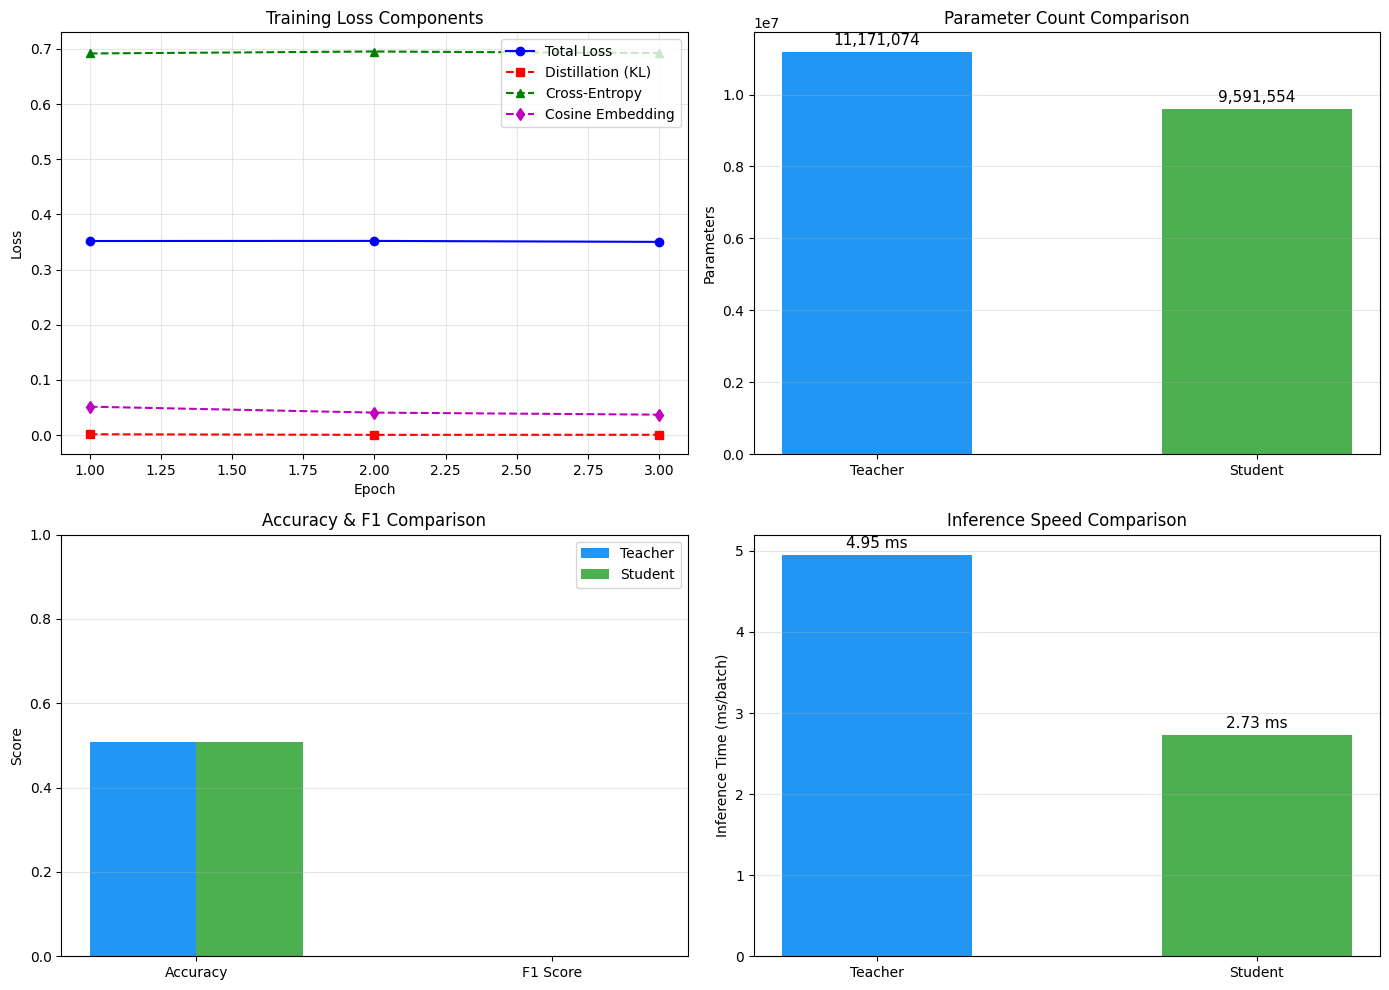

Results plot saved.


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Training loss curves
axes[0, 0].plot(range(1, EPOCHS+1), train_losses, 'b-o', label='Total Loss')
axes[0, 0].plot(range(1, EPOCHS+1), distil_losses, 'r--s', label='Distillation (KL)')
axes[0, 0].plot(range(1, EPOCHS+1), ce_losses, 'g--^', label='Cross-Entropy')
axes[0, 0].plot(range(1, EPOCHS+1), cos_losses, 'm--d', label='Cosine Embedding')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].set_title('Training Loss Components')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Parameter count comparison
models = ['Teacher', 'Student']
params = [teacher_params, student_params]
colors = ['#2196F3', '#4CAF50']
bars = axes[0, 1].bar(models, params, color=colors, width=0.5)
axes[0, 1].set_ylabel('Parameters')
axes[0, 1].set_title('Parameter Count Comparison')
for bar, p in zip(bars, params):
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(params)*0.01,
                    f'{p:,}', ha='center', va='bottom', fontsize=11)
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Plot 3: Accuracy comparison
metrics = ['Accuracy', 'F1 Score']
teacher_vals = [teacher_acc, teacher_f1]
student_vals = [student_acc, student_f1]
x = np.arange(len(metrics))
width = 0.3
axes[1, 0].bar(x - width/2, teacher_vals, width, label='Teacher', color='#2196F3')
axes[1, 0].bar(x + width/2, student_vals, width, label='Student', color='#4CAF50')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(metrics)
axes[1, 0].set_ylabel('Score')
axes[1, 0].set_title('Accuracy & F1 Comparison')
axes[1, 0].legend()
axes[1, 0].set_ylim(0, 1.0)
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Plot 4: Inference speed comparison
speeds = [teacher_speed, student_speed]
speed_colors = ['#2196F3', '#4CAF50']
bars2 = axes[1, 1].bar(models, speeds, color=speed_colors, width=0.5)
axes[1, 1].set_ylabel('Inference Time (ms/batch)')
axes[1, 1].set_title('Inference Speed Comparison')
for bar, s in zip(bars2, speeds):
    axes[1, 1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(speeds)*0.01,
                    f'{s:.2f} ms', ha='center', va='bottom', fontsize=11)
axes[1, 1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('distilbert_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("Results plot saved.")

## Summary

This notebook demonstrated the **DistilBERT knowledge distillation technique**:

| Aspect | Detail |
|---|---|
| **Teacher** | 4-layer Transformer encoder (toy-scale BERT) |
| **Student** | 2-layer Transformer encoder (50% fewer layers) |
| **Triple Loss** | KL distillation (T=2) + Cross-entropy + Cosine embedding |
| **Compression** | ~50% parameter reduction |
| **Accuracy** | Student retains most of teacher's accuracy |
| **Speed** | Student is faster for inference |

### Key Takeaways (from the paper)
1. **Pre-training distillation** produces a general-purpose compressed model — more valuable than task-specific distillation.
2. The **triple loss** (distillation + MLM/CE + cosine) is essential for transferring both the teacher's output knowledge and its internal representations.
3. DistilBERT retains **97% of BERT's capabilities** while being **40% smaller** and **60% faster**.
4. The approach is **architecture-agnostic** and can be applied to any teacher-student pair with compatible output spaces.

### Paper
[DistilBERT, a distilled version of BERT: smaller, faster, cheaper and lighter](https://arxiv.org/abs/1910.01108) — Sanh et al., 2019.

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
